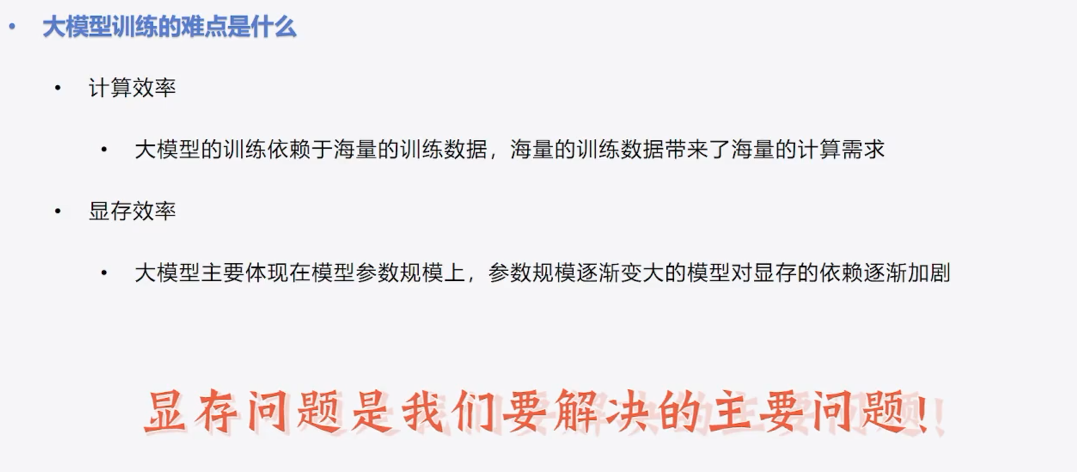

https://mp.weixin.qq.com/s/4Pu-9KA6uf5vug8YMiWGpA

https://mp.weixin.qq.com/s/PPu3eoT9qtvyRFKLDH7DKw

https://mp.weixin.qq.com/s/3OSNleBWdjG3fWlala4OHw

https://mp.weixin.qq.com/s/qP-kwJFPouMtAGUEVInPzA

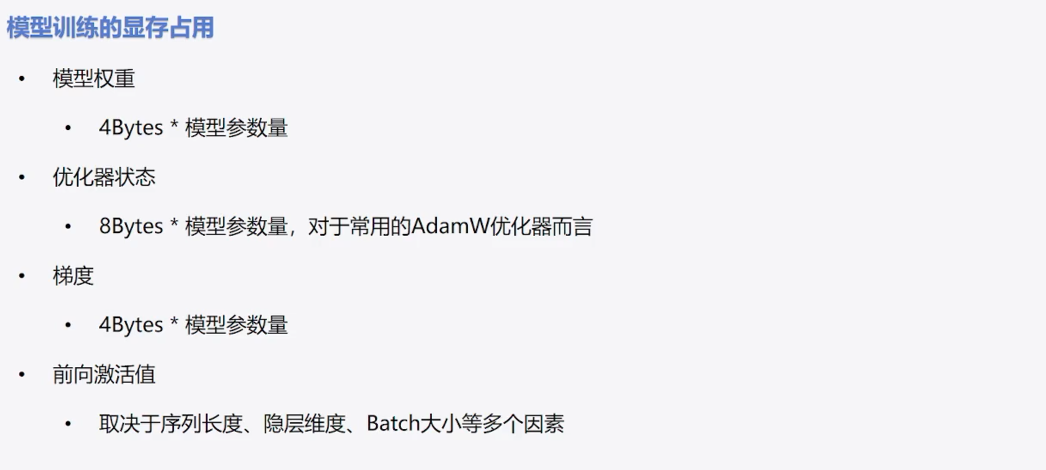

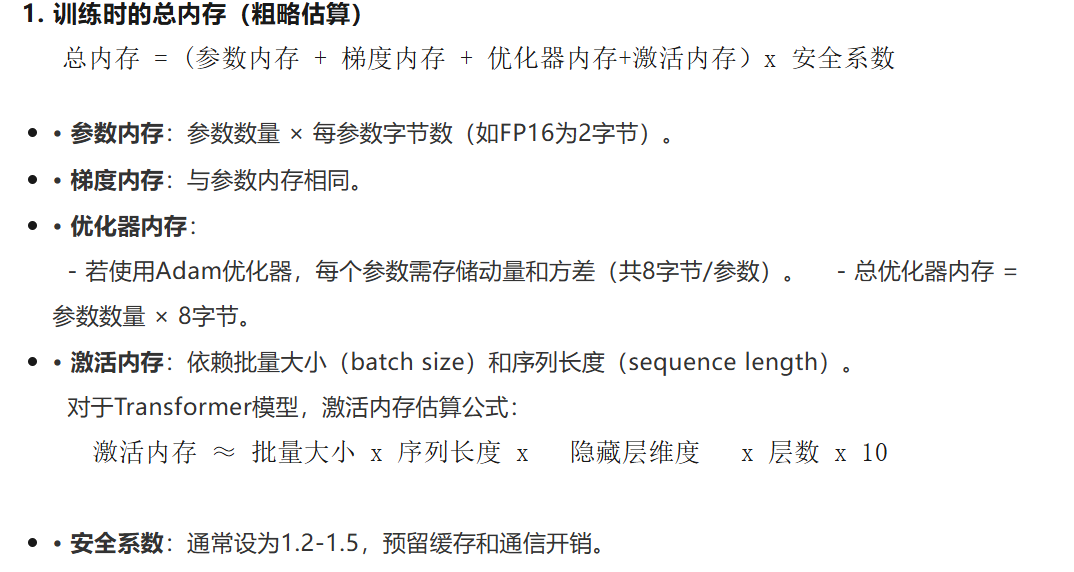

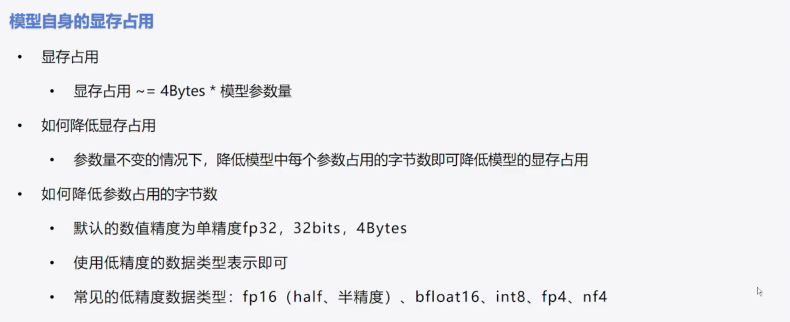

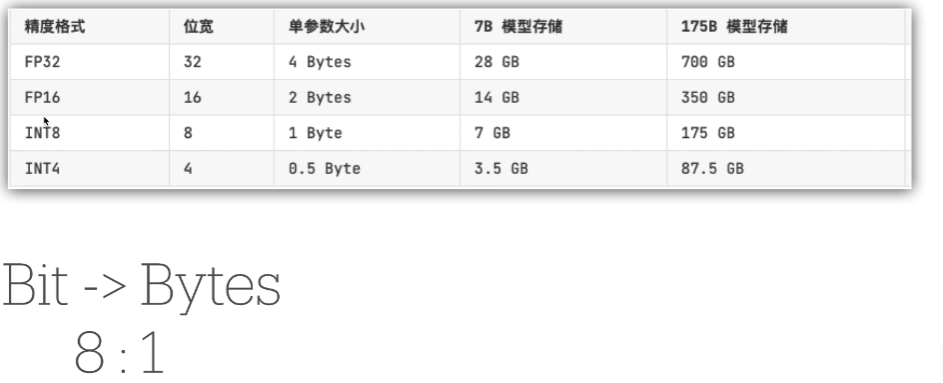

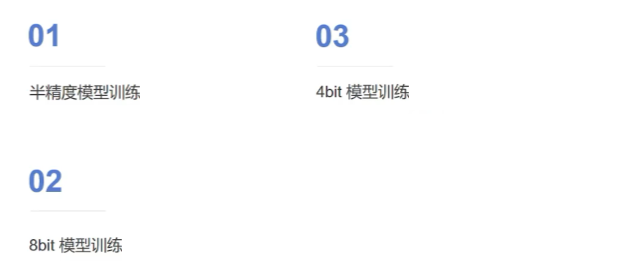

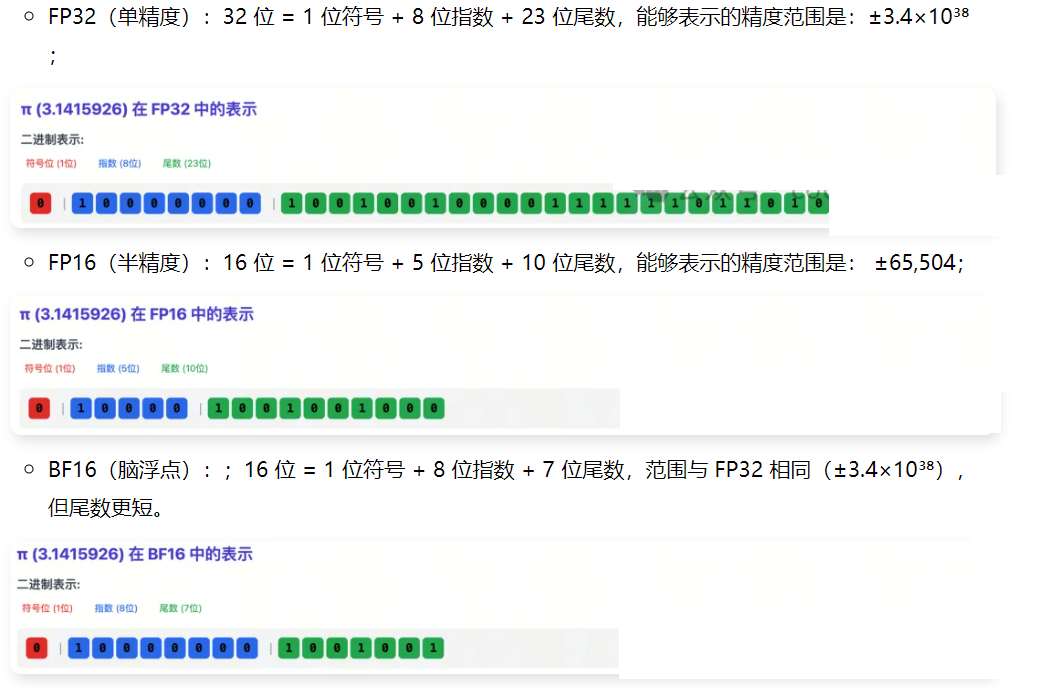

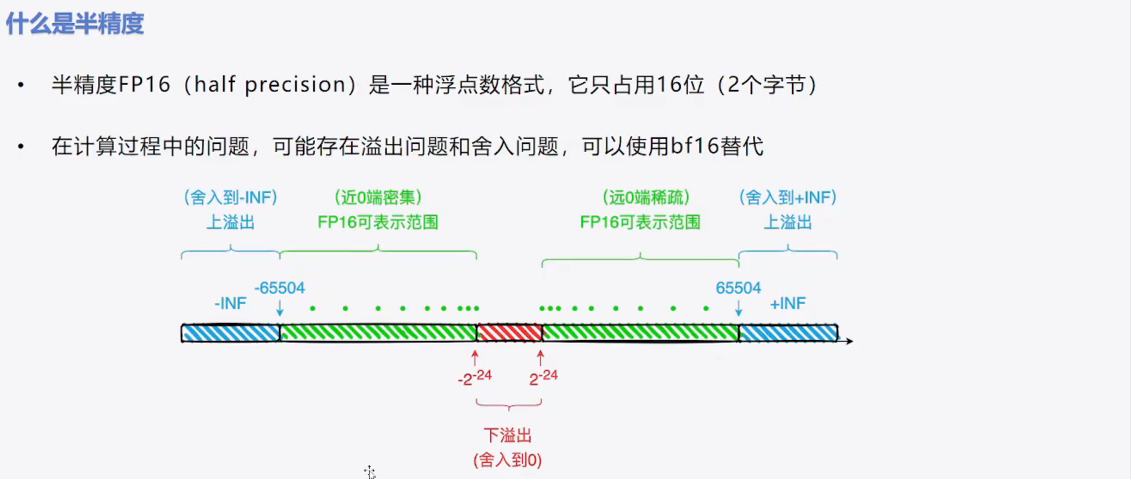

+ 上溢出:超出了数据类型所能表示的最大范围

+ 下溢出:结果小于数据类型所能表示的最小范围，导致精度丢失或结果不准确。

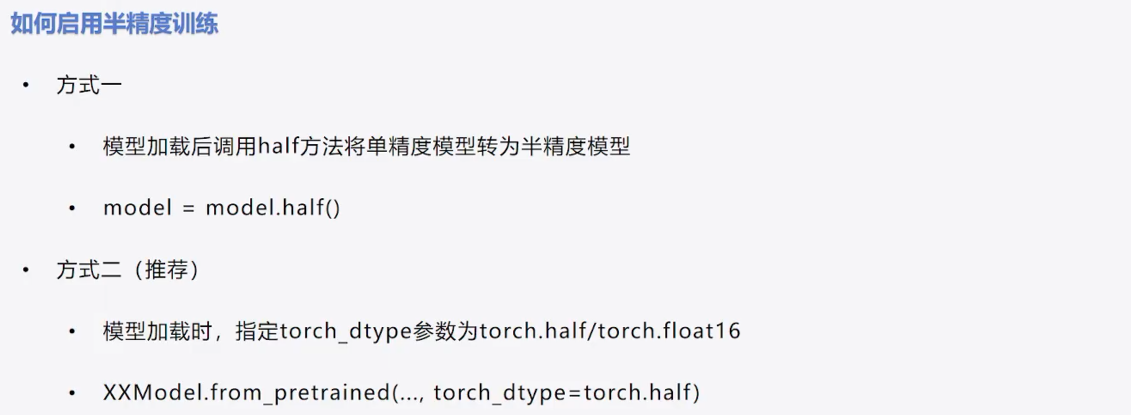

In [ ]:
#加载模型
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    local_files_only = True, #仅从本地文件加载模型
    torch_dtype=torch.bfloat16
)

## int8量化

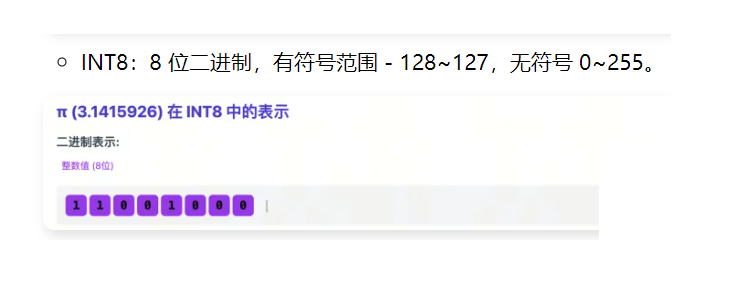

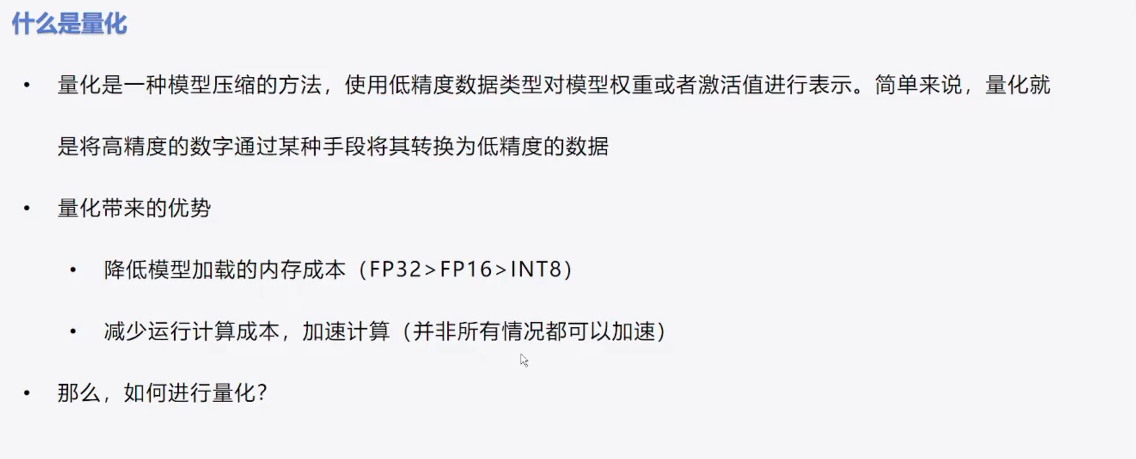

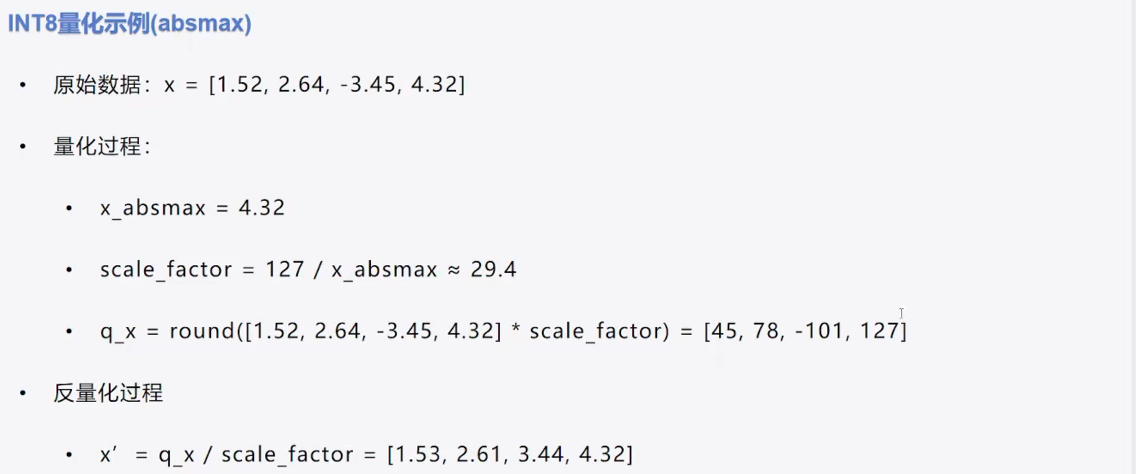

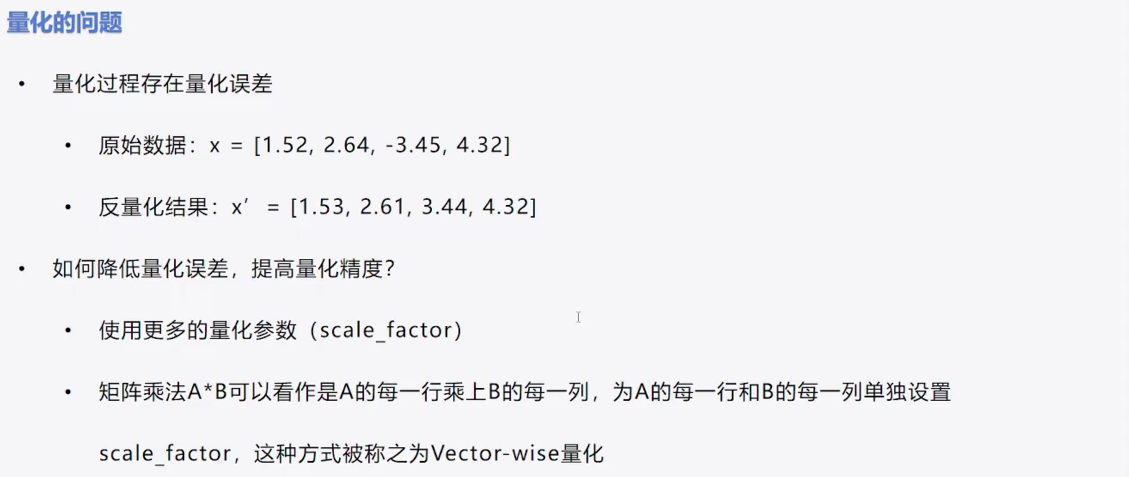

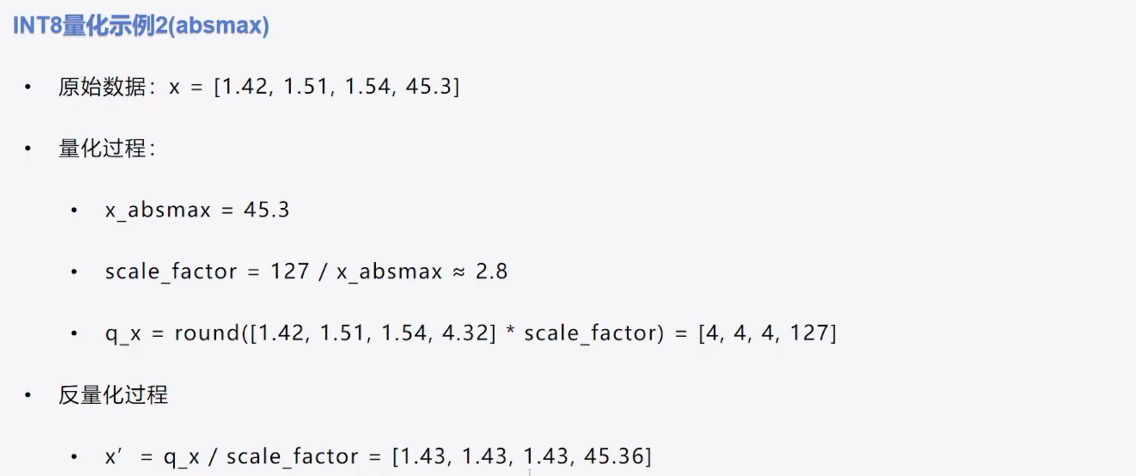

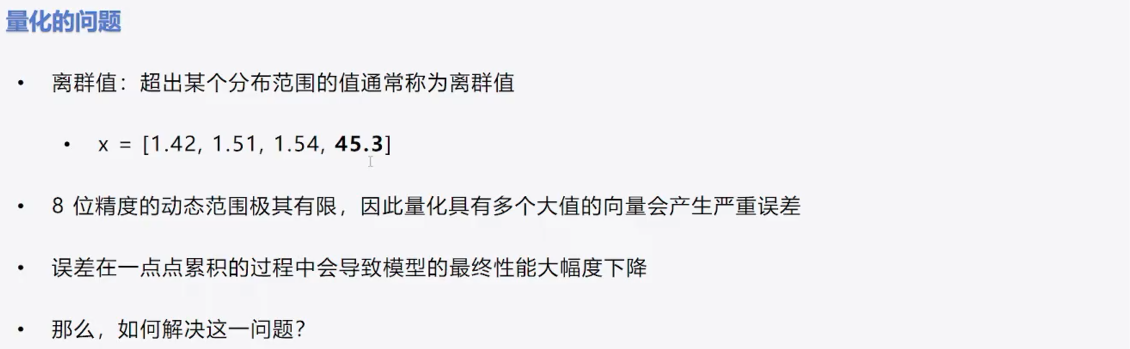

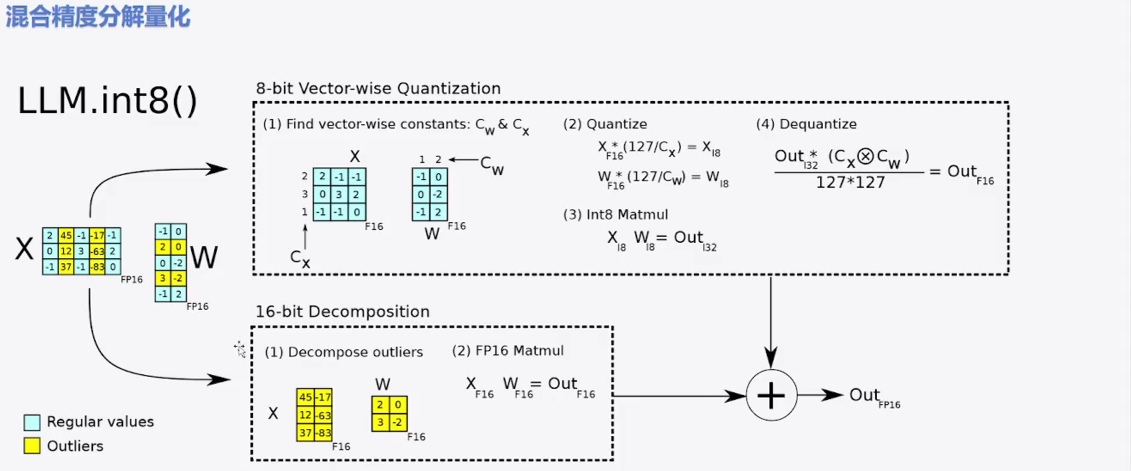

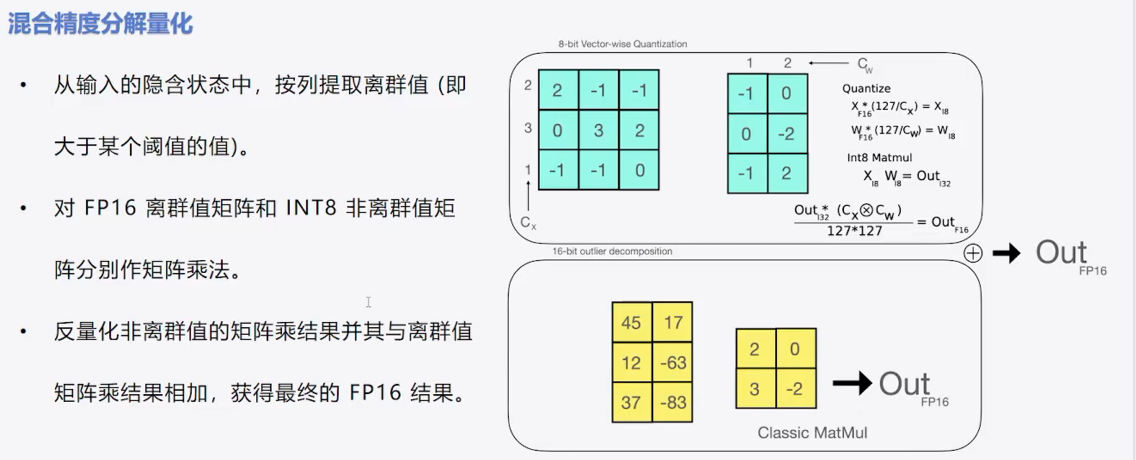

https://mp.weixin.qq.com/s?__biz=Mzk0MDMwMzQyOA==&mid=2247503867&idx=1&sn=cda9ff0677fb4d949c69275bee2dd8ba&token=1903561860&lang=zh_CN&scene=21&poc_token=HJ6ylGij0QUkdHGHzYd-MrgsfsTiMOhWqAPtJXxd

In [ ]:
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    local_files_only = True, #仅从本地文件加载模型
    torch_dtype=torch.bfloat16,
    #使用int8加载模型
    load_in_8bit=True
)


## int4量化


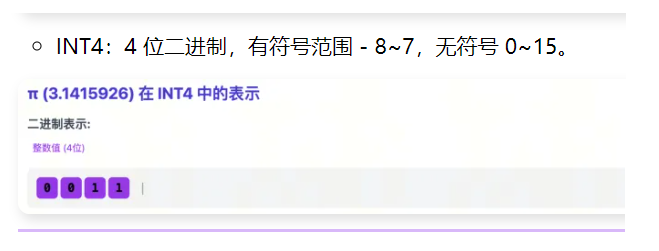

https://mp.weixin.qq.com/s?__biz=MjM5MzQ5NTU0Mw==&mid=2455052254&idx=1&sn=0655a59d8d630bdd204893b59096560d&scene=21#wechat_redirect

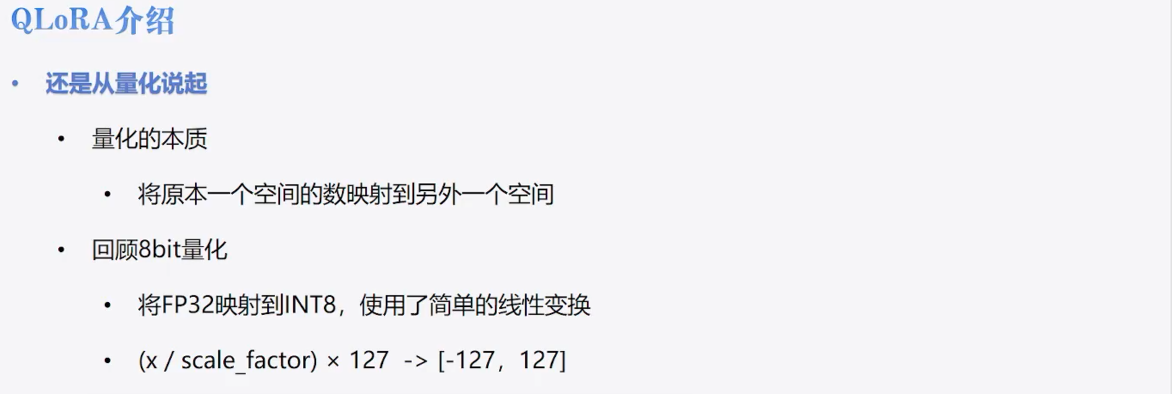

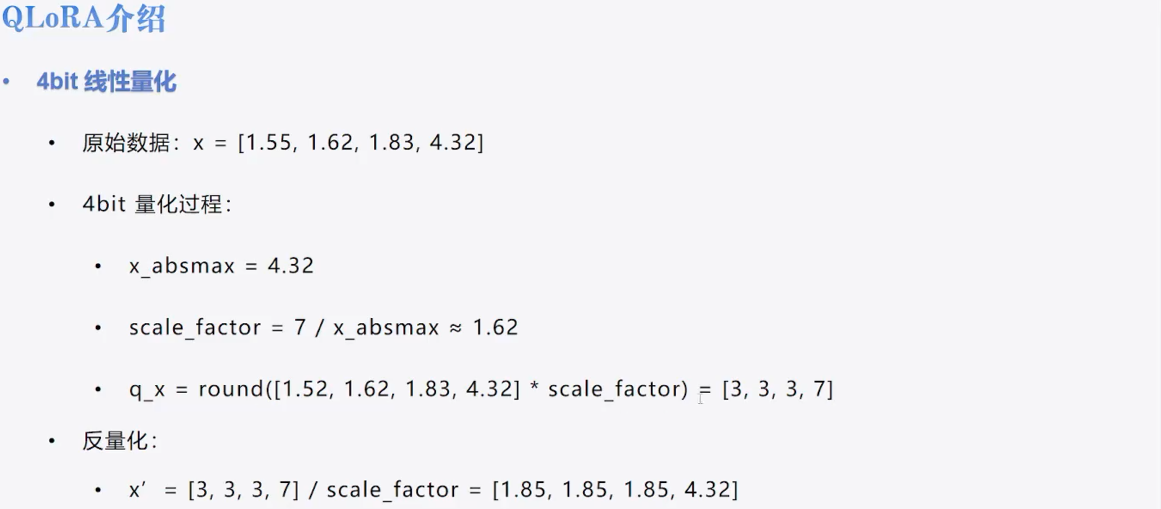

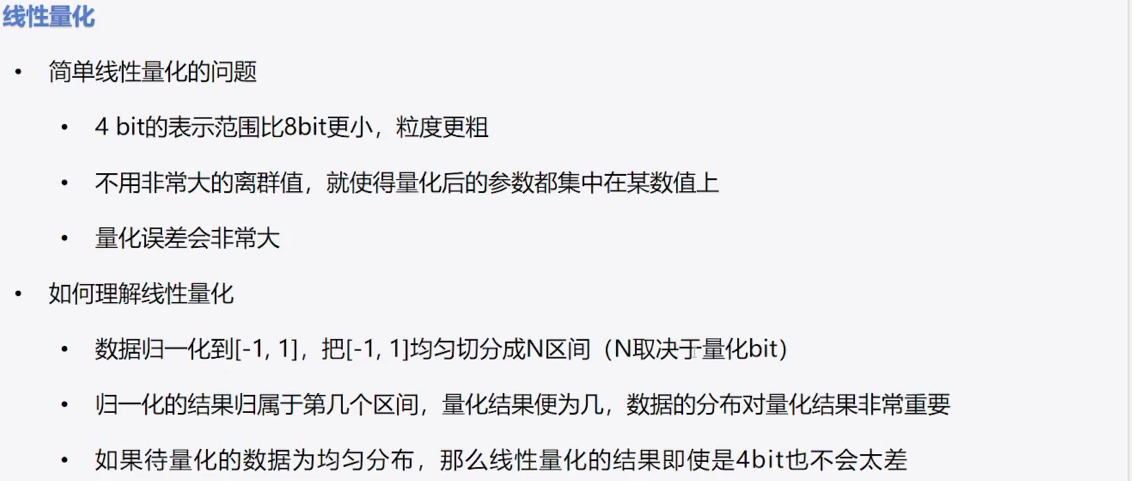

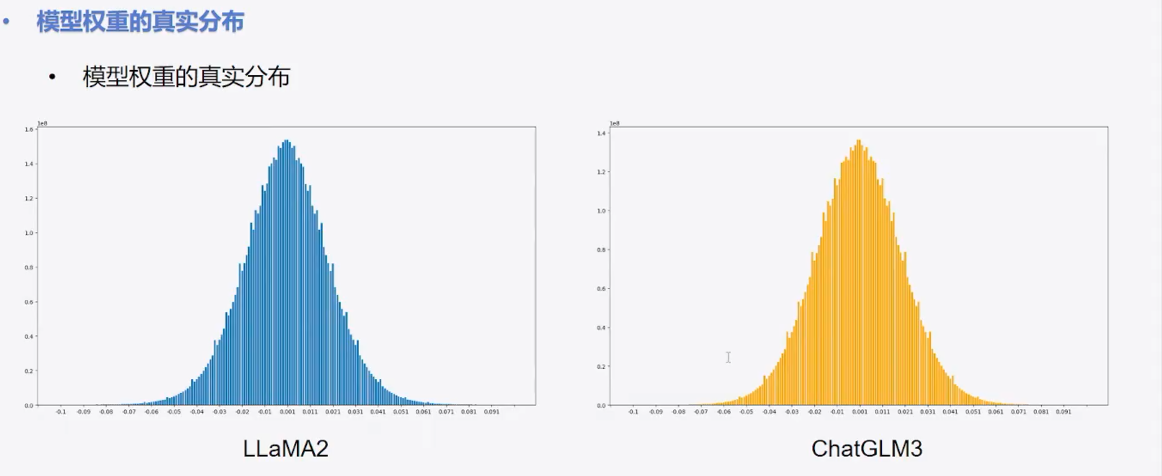

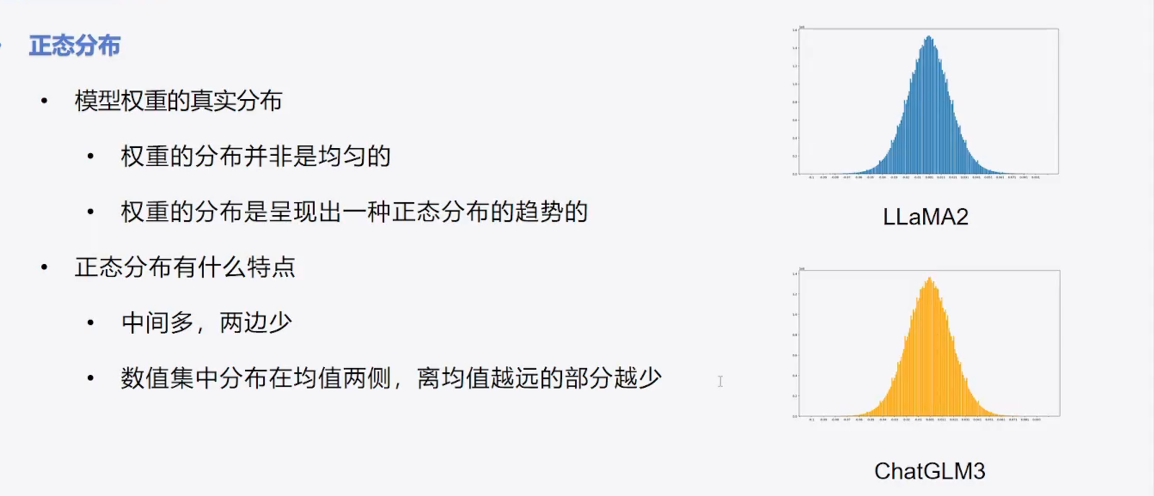

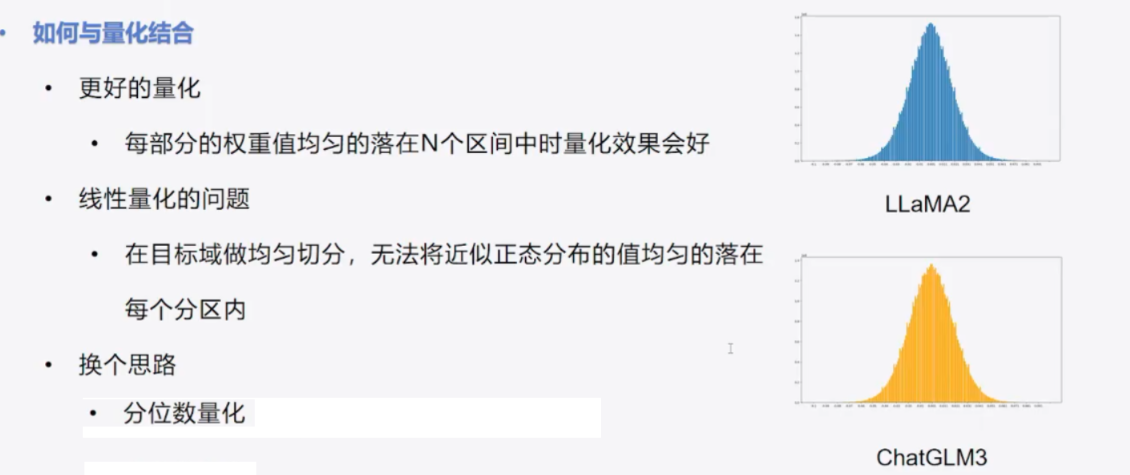

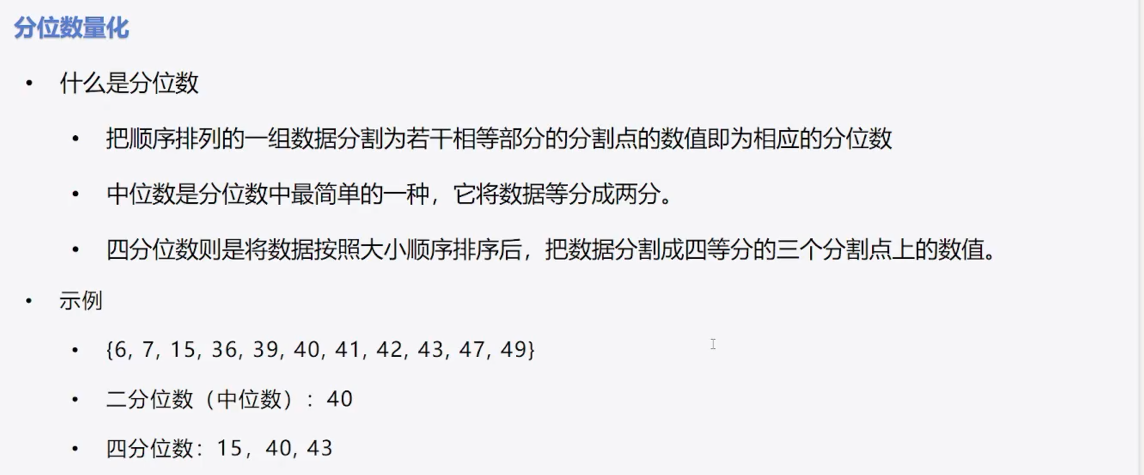

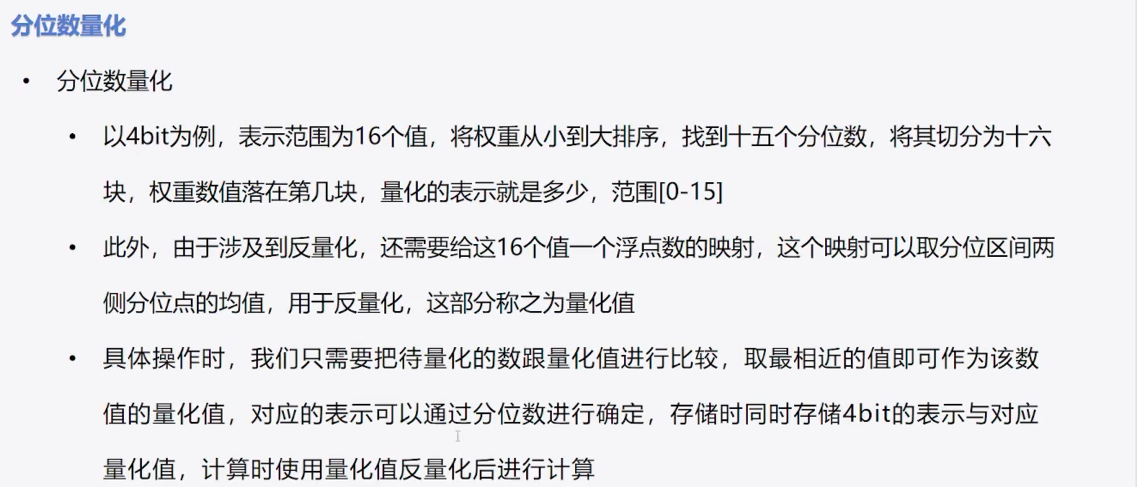

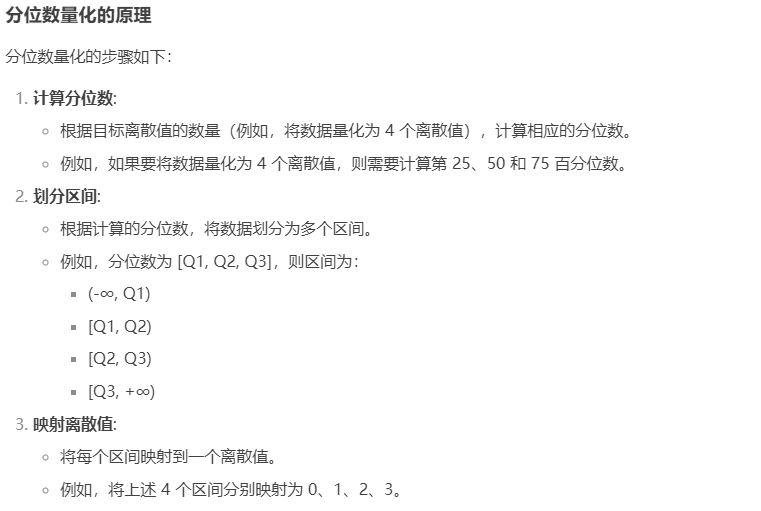

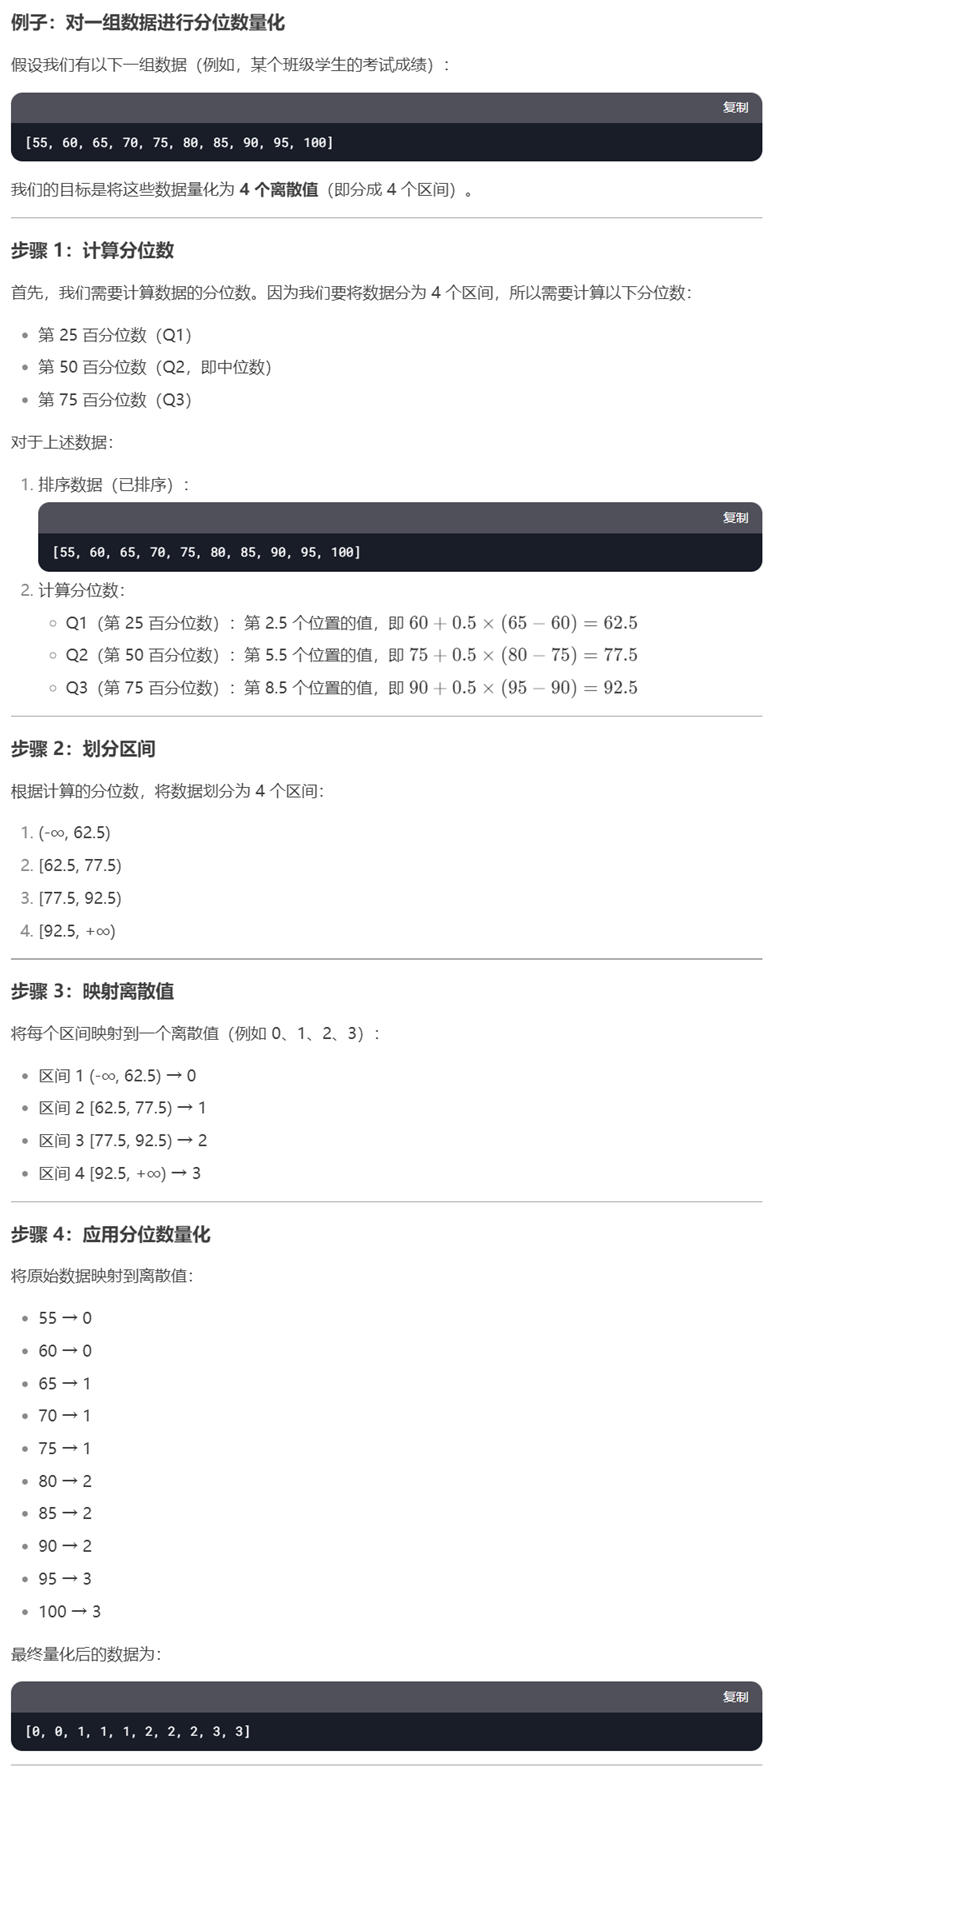

In [1]:
import pandas as pd

# 原始数据
data = [55, 60, 65, 70, 75, 80, 85, 90, 95, 100]

# 创建 DataFrame
df = pd.DataFrame(data, columns=['score'])

# 分位数量化：将数据量化为 4 个离散值
df['quantile_bin'] = pd.qcut(df['score'], q=4, labels=False)

print(df)

   score  quantile_bin
0     55             0
1     60             0
2     65             0
3     70             1
4     75             1
5     80             2
6     85             2
7     90             3
8     95             3
9    100             3


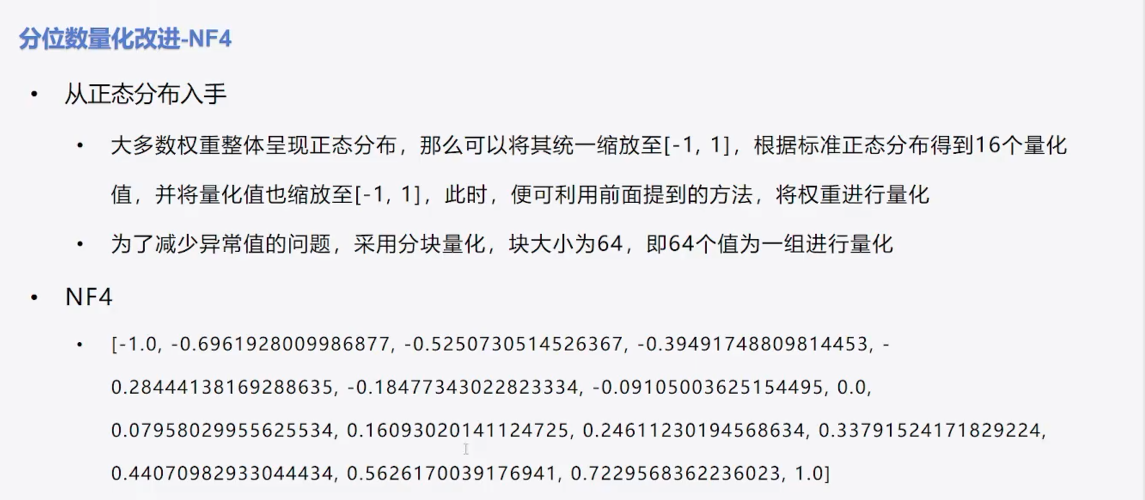

NF4（NormalFloat4）在主流实现（比如 bitsandbytes 的 4bit QLoRA）里，不会每个分组/块都存一张“检索表”，而是共用同一张固定的 16 个码本（codebook / dequant table）。
共用的部分：NF4 的 16 个离散取值（码本）是固定的，通常在内核里作为常量/查表使用，所有分组共享。
每个分组单独存的部分：一般只存该分组的缩放因子 scale（常见叫 absmax/scale）（有的量化方案还会有 zero-point，但 NF4 常见是配合 scale 的对称形式）。
double quant（双量化）时：额外把这些 per-group 的 scale 再量化压缩，但本质仍是“共享码本 + 每组少量参数”，不是“每组一张表”。


分组量化：
对权重做 4bit 量化时，不是整层共用一套量化尺度（scale/zero-point），而是把权重按某个维度切成很多组；每 128 个权重元素（或每 128 列/通道，具体看实现）共享同一组 scale/zero-point。

### 量化具体流程

```
原始权重（FP32）
    ↓
步骤1: 数据标准化
    ↓
标准化值（-1 到 1）
    ↓
步骤2: 计算分位数码本
    ↓
NF4码本（16个值）
    ↓
步骤3: 映射到最近量化值
    ↓
4-bit索引（0-15）
    ↓
保存：索引 + 码本 + scale
```

量化样例
```
原始数据: 2.3

步骤1: 标准化
  min = -3.2, max = 2.3
  标准化值 = 2×(2.3-(-3.2))/(2.3-(-3.2)) - 1
           = 2×5.5/5.5 - 1
           = 1.0

步骤2: 查找最近码本值
  码本值: [..., 0.866, 1.094, 1.407]
  |1.0 - 0.866| = 0.134
  |1.0 - 1.094| = 0.094  ← 最小
  |1.0 - 1.407| = 0.407
  
步骤3: 保存索引
  索引 = 14 (4-bit)

保存信息:
  - 索引: 14 (4-bit)
  - scale: 2.75
  - min: -3.2
```

---

### 反量化流程

```
4-bit索引
    ↓
步骤1: 查码本
    ↓
标准化量化值
    ↓
步骤2: 反标准化
    ↓
还原的FP16/FP32值
    ↓
用于计算
```

反量化完整示例

```
已保存信息:
  - 索引: 14
  - scale: 2.75
  - min: -3.2
  - NF4码本: [固定值]

步骤1: 查码本
  码本[14] = 1.094

步骤2: 反标准化
  原始值 = (1.094 + 1) × 2.75 + (-3.2)
         = 2.5585

结果:
  原始值: 2.3
  还原值: 2.5585
  误差: 0.2585 (约11%)
```

---

### 双重量化

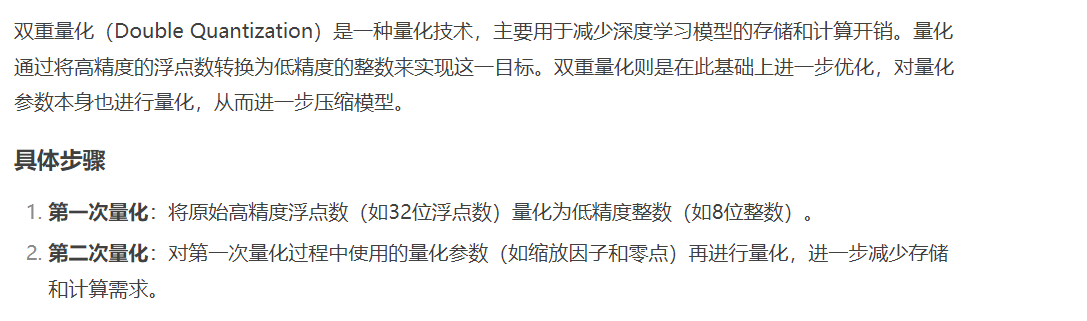

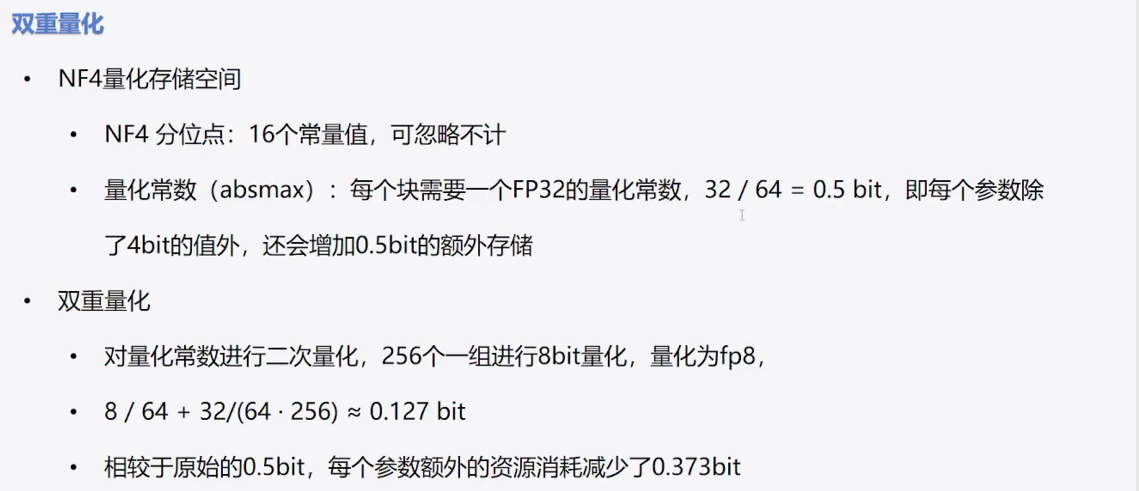

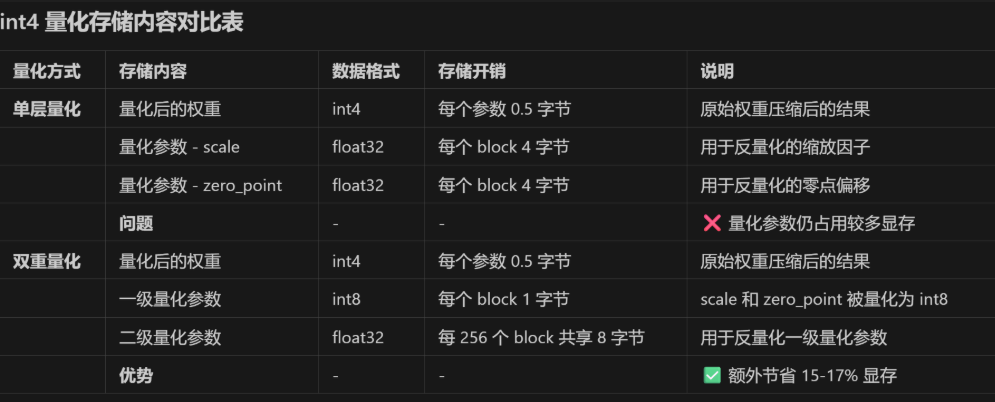

### 分页优化器

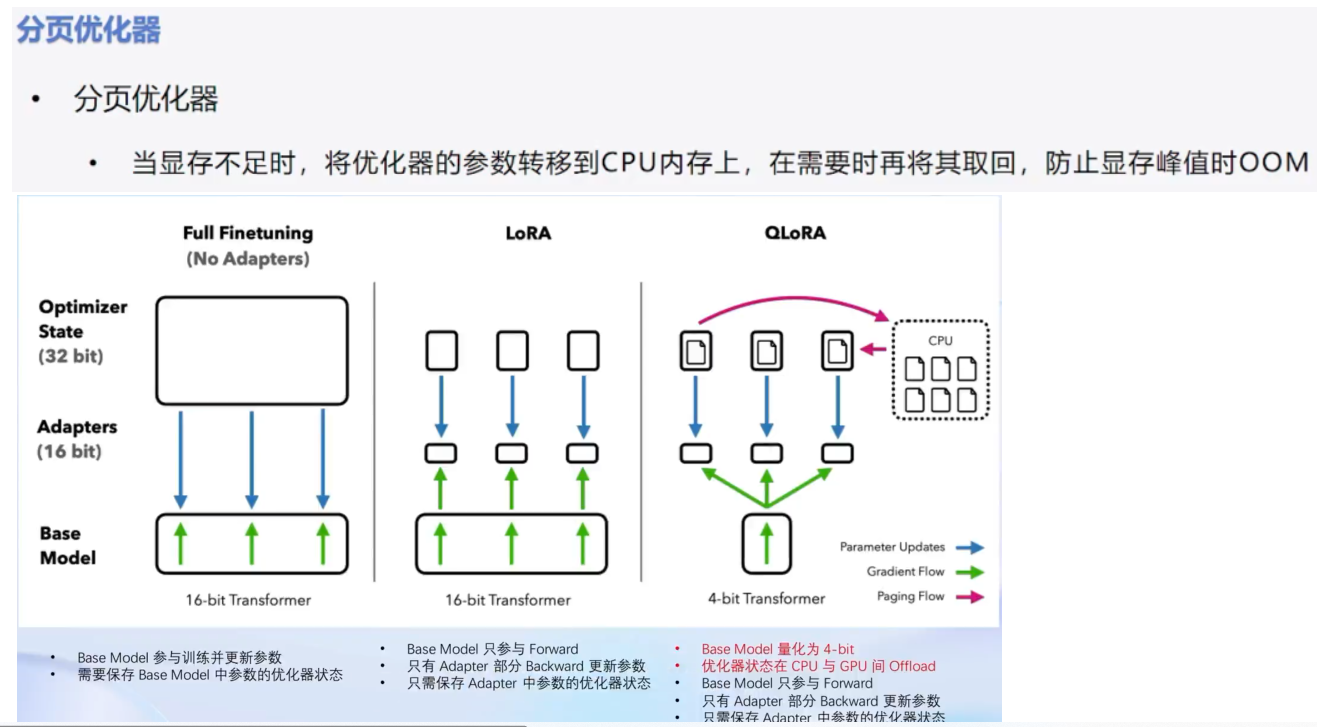

## 实现代码

In [ ]:

#pip install bitsandbytes


from transformers import BitsAndBytesConfig
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    local_files_only = True, #仅从本地文件加载模型
    device_map="auto",
    torch_dtype = torch.float16,
    quantization_config = BitsAndBytesConfig(
        load_in_4bit =True,
        bnb_4bit_use_double_type = True,
        bnb_4bit_quant_type = "nf4",
        bnb_4bit_compute_dtype = torch.float16
    )
)


model = AutoModelForCausalLM.from_pretrained(
    "model_name",
    load_in_8bit=True,  # 启用 INT8 量化
    device_map="auto"
)